In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [11]:
mag7 = pd.read_csv("Mag7 Monthly Returns.csv")

In [12]:
mag7.head()
mag7.columns
mag7.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 847 entries, 0 to 846
Data columns (total 5 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0   (tic) Ticker Symbol                                       847 non-null    object 
 1   (datadate) Data Date - Security Monthly                   847 non-null    object 
 2   (gvkey) Global Company Key - Security Monthly Descriptor  847 non-null    int64  
 3   (conm) Company Name                                       847 non-null    object 
 4   (trt1m) Monthly Total Return                              847 non-null    float64
dtypes: float64(1), int64(1), object(3)
memory usage: 33.2+ KB


In [13]:
mag7.columns
mag7.head()

,(tic) Ticker Symbol,(datadate) Data Date - Security Monthly,(gvkey) Global Company Key - Security Monthly Descriptor,(conm) Company Name,(trt1m) Monthly Total Return
0,AAPL,31.12.2015,1690,APPLE INC,-11.0228
1,AAPL,31.01.2016,1690,APPLE INC,-7.5242
2,AAPL,29.02.2016,1690,APPLE INC,-0.1336
3,AAPL,31.03.2016,1690,APPLE INC,12.7211
4,AAPL,30.04.2016,1690,APPLE INC,-13.9921


In [14]:
mag7 = mag7[[
    "(tic) Ticker Symbol",
    "(datadate) Data Date - Security Monthly",
    "(trt1m) Monthly Total Return"
]]

In [15]:
mag7.columns = ["ticker", "date", "trt1m"]

In [16]:
mag7["date"] = pd.to_datetime(
    mag7["date"],
    format="%d.%m.%Y"
)

In [17]:
mag7.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 847 entries, 0 to 846
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   ticker  847 non-null    object        
 1   date    847 non-null    datetime64[ns]
 2   trt1m   847 non-null    float64       
dtypes: datetime64[ns](1), float64(1), object(1)
memory usage: 20.0+ KB


In [18]:
mag7["ret_dec"] = mag7["trt1m"] / 100

In [19]:
mag7["ret_dec"].describe()

count    847.000000
mean       0.028942
std        0.110324
min       -0.367334
25%       -0.037288
50%        0.023217
75%        0.083243
max        0.741452
Name: ret_dec, dtype: float64

In [20]:
import numpy as np

mag7["log_ret"] = np.log(1 + mag7["ret_dec"])

In [21]:
mag7["log_ret"].describe()

count    847.000000
mean       0.022908
std        0.105959
min       -0.457813
25%       -0.038000
50%        0.022952
75%        0.079959
max        0.554719
Name: log_ret, dtype: float64

In [22]:
mag7_avg = (
    mag7
    .groupby("date")["log_ret"]
    .mean()
    .rename("mag7_ret")
    .reset_index()
)

In [23]:
mag7_avg.head()

,date,mag7_ret
0,2015-12-31,0.003407
1,2016-01-31,-0.074812
2,2016-02-29,-0.023795
3,2016-03-31,0.101130
4,2016-04-30,-0.021196


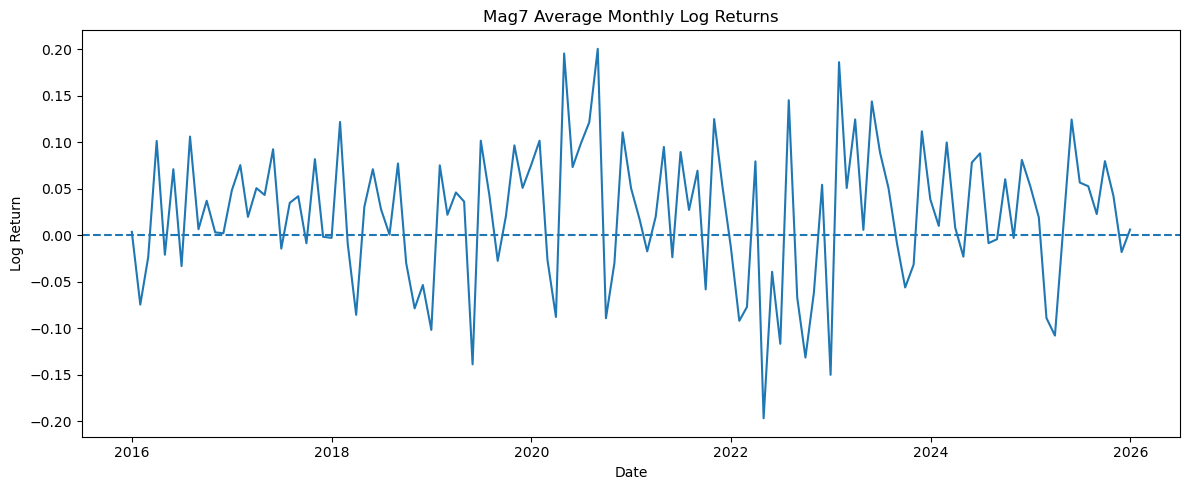

In [24]:
import matplotlib.pyplot as plt

# make sure date is index
mag7_avg = mag7_avg.set_index("date")

plt.figure(figsize=(12,5))
plt.plot(mag7_avg.index, mag7_avg["mag7_ret"])
plt.axhline(0, linestyle="--")
plt.title("Mag7 Average Monthly Log Returns")
plt.ylabel("Log Return")
plt.xlabel("Date")
plt.tight_layout()
plt.show()

In [25]:
mag7_avg.describe()

,mag7_ret
count,121.000000
mean,0.022908
std,0.073652
min,-0.197029
25%,-0.021196
50%,0.026927
75%,0.075163
max,0.200230


In [26]:
mag7_avg.head()

,mag7_ret
date,
2015-12-31,0.003407
2016-01-31,-0.074812
2016-02-29,-0.023795
2016-03-31,0.101130
2016-04-30,-0.021196


In [27]:
mag7_avg = mag7_avg.reset_index()
mag7_avg.to_csv("mag7_clean.csv", index=False)